# Timeseries — VAR (beberapa deret saling mempengaruhi, diramal bersama)
**Kapan dipakai:** beberapa deret yang saling terkait (inflasi, kurs, suku bunga) dan semuanya
harus diramal, tanpa nilai masa depan dari luar.

**Langkah:** uji stasioner (ADF) → log + differencing → pilih jumlah lag (AIC) → ramal →
kembalikan ke skala asli → MAE per variabel vs naive. Bonus: uji Granger (apakah X membantu
meramal Y?).

**Data demo:** makro ekonomi AS kuartalan (`realgdp`, `realcons`, `realinv`, `unemp`, `infl`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/timeseries/forecasting"   # GANTI saat lomba
SERIES_CSV = f"{DATA_FOLDER}/macro_quarterly.csv"

DATE_COL = "date"
LOG_COLS = ["realgdp", "realcons", "realinv"]   # deret level positif → log lalu diff
PLAIN_COLS = ["unemp", "infl"]                  # deret persen → diff saja
GRANGER_CAUSE = "realinv"     # apakah kolom ini membantu meramal ...
GRANGER_TARGET = "realgdp"    # ... kolom ini?
FREQUENCY = "QS"
HORIZON = 8          # jumlah kuartal ramalan, data uji = HORIZON titik terakhir
MAX_LAG = 8

## Baca data

(203, 5) | missing: 0


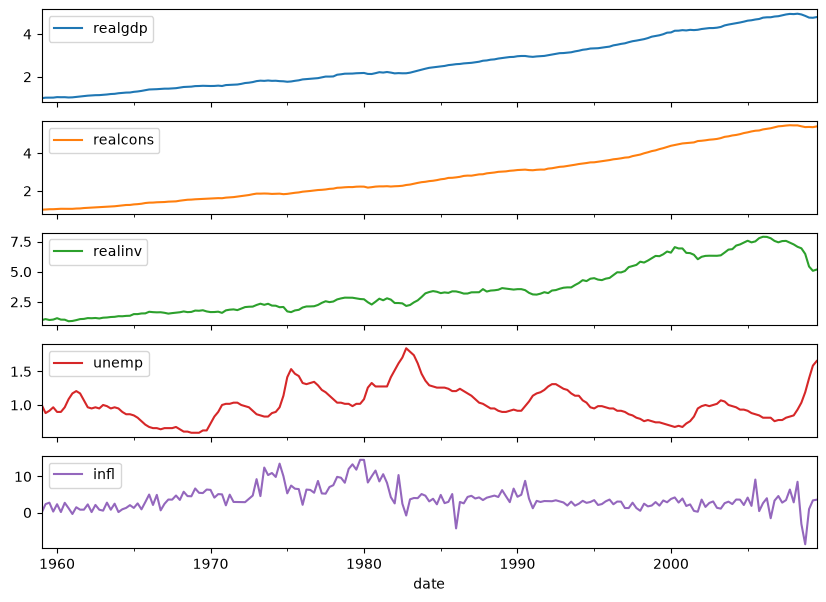

In [3]:
table = pd.read_csv(SERIES_CSV, parse_dates=[DATE_COL], index_col=DATE_COL)
table = table[LOG_COLS + PLAIN_COLS].asfreq(FREQUENCY)
missing = table.isna().sum()
print(table.shape, "| missing:", missing.sum())
(table / table.iloc[0].abs().clip(lower=1)).plot(subplots=True, figsize=(10, 7))
plt.show()

## Uji stasioner ADF: p < 0.05 → stasioner (boleh masuk VAR)

In [4]:
transformed = pd.concat([np.log(table[LOG_COLS]), table[PLAIN_COLS]], axis=1)
differenced = transformed.diff().dropna()
for column in table.columns:
    p_original = adfuller(table[column])[1]
    p_differenced = adfuller(differenced[column])[1]
    print(column, "| p asli", round(p_original, 3), "| p setelah diff", round(p_differenced, 3))

realgdp | p asli 0.998 | p setelah diff 0.0
realcons | p asli 0.998 | p setelah diff 0.0
realinv | p asli 0.648 | p setelah diff 0.0
unemp | p asli 0.107 | p setelah diff 0.001
infl | p asli 0.03 | p setelah diff 0.0


C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_6568\199166892.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_original = adfuller(table[column])[1]
C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_6568\199166892.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_differenced = adfuller(differenced[column])[1]
C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_6568\19916689

## Split waktu

In [5]:
train = differenced.iloc[:-HORIZON]
test = table.iloc[-HORIZON:]
last_train_values = transformed.iloc[-HORIZON - 1]     # nilai (log) terakhir sebelum uji
print("latih:", train.shape, "| uji:", test.shape)

latih: (194, 5) | uji: (8, 5)


## Model
Pilih SATU cara memilih lag: hapus `#` di baris yang ingin dipakai, beri `#` pada baris AIC.

In [6]:
var = VAR(train)
print(var.select_order(MAX_LAG).summary())
model = var.fit(maxlags=MAX_LAG, ic="aic")
# model = var.fit(maxlags=MAX_LAG, ic="bic")
# model = var.fit(maxlags=MAX_LAG, ic="hqic")
# model = var.fit(2)                          # jumlah lag ditulis langsung
print("lag terpilih:", model.k_ar)

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -29.07      -28.98   2.382e-13      -29.03
1      -30.13     -29.61*   8.200e-14      -29.92
2      -30.36      -29.41   6.519e-14     -29.98*
3     -30.38*      -29.00  6.392e-14*      -29.82
4      -30.31      -28.48   6.929e-14      -29.57
5      -30.22      -27.96   7.604e-14      -29.30
6      -30.17      -27.48   7.997e-14      -29.08
7      -30.11      -26.99   8.608e-14      -28.84
8      -30.02      -26.47   9.481e-14      -28.58
-------------------------------------------------
lag terpilih: 3


## Ramal lalu kembalikan ke skala asli
Diff dijumlah kumulatif + nilai terakhir, lalu `exp` untuk kolom log.

In [7]:
def undo_transform(differenced_forecast, last_values):
    level = differenced_forecast.cumsum() + last_values
    level[LOG_COLS] = np.exp(level[LOG_COLS])
    return level


recent = train.to_numpy()[-model.k_ar:]     # k_ar baris terakhir = input ramalan
forecast = model.forecast(recent, steps=HORIZON)
forecast = pd.DataFrame(forecast, index=test.index, columns=differenced.columns)
predictions = undo_transform(forecast, last_train_values)
predictions.round(2)

,realgdp,realcons,realinv,unemp,infl
date,,,,,
2007-10-01,13360.76,9407.67,2127.92,4.79,2.71
2008-01-01,13446.90,9466.40,2141.53,4.87,3.17
2008-04-01,13530.98,9525.05,2155.59,4.95,3.11
2008-07-01,13617.16,9600.20,2156.95,5.04,2.53
2008-10-01,13714.56,9674.58,2173.88,5.09,2.85
2009-01-01,13818.66,9755.84,2193.68,5.12,2.66
2009-04-01,13924.82,9839.14,2212.53,5.15,2.56
2009-07-01,14038.51,9924.70,2237.26,5.16,2.63


## Evaluasi: MAE per variabel, VAR vs naive (nilai terakhir)
Data demo: periode uji = krisis 2008, VAR (yang meneruskan tren) kalah dari naive untuk GDP.
Itu wajar, guncangan besar tidak bisa diramal. Selalu laporkan pembanding naive.

          MAE_VAR  MAE_naive  MAPE_VAR_%
realgdp   507.023    192.351       3.894
realcons  376.521     77.275       4.077
realinv   352.073    343.647      22.241
unemp       1.840      2.162      22.279
infl        3.778      3.774      84.851


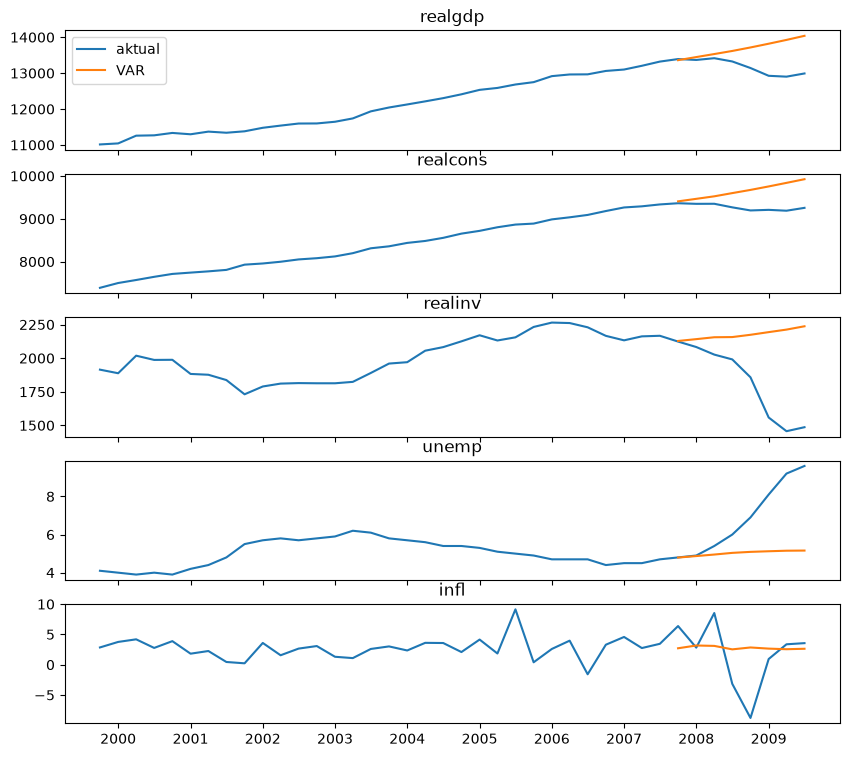

In [8]:
naive = table.iloc[-HORIZON - 1]
mae_var = []
mae_naive = []
mape_var = []
for column in table.columns:
    mae_var.append(mean_absolute_error(test[column], predictions[column]))
    mae_naive.append(mean_absolute_error(test[column], np.repeat(naive[column], HORIZON)))
    relative_error = abs(test[column] - predictions[column]) / abs(test[column])
    mape_var.append(100 * relative_error.mean())
scores = pd.DataFrame(index=table.columns)
scores["MAE_VAR"] = mae_var
scores["MAE_naive"] = mae_naive
scores["MAPE_VAR_%"] = mape_var
print(scores.round(3))

fig, axes = plt.subplots(len(table.columns), 1, figsize=(10, 9), sharex=True)
for ax, column in zip(axes, table.columns):
    ax.plot(table[column].iloc[-40:], label="aktual")
    ax.plot(predictions[column], label="VAR")
    ax.set_title(column)
axes[0].legend()
plt.show()

## Uji Granger: apakah `GRANGER_CAUSE` membantu meramal `GRANGER_TARGET`? (p < 0.05 → ya)

In [9]:
granger = grangercausalitytests(differenced[[GRANGER_TARGET, GRANGER_CAUSE]], maxlag=4)
for lag in granger:
    p_value = granger[lag][0]["ssr_ftest"][1]
    print("lag", lag, ": p =", round(p_value, 4))

lag 1 : p = 0.1809
lag 2 : p = 0.09
lag 3 : p = 0.1614
lag 4 : p = 0.1787


## Latih ulang di semua data + hasil ramalan ke depan

In [10]:
model = VAR(differenced).fit(model.k_ar)
future_dates = pd.date_range(start=table.index[-1], periods=HORIZON + 1, freq=FREQUENCY)[1:]
forecast = model.forecast(differenced.to_numpy()[-model.k_ar:], steps=HORIZON)
forecast = pd.DataFrame(forecast, index=future_dates, columns=differenced.columns)
future_values = undo_transform(forecast, transformed.iloc[-1])

result = pd.DataFrame()
result["tanggal"] = future_dates
for column in table.columns:
    result[column] = future_values[column].to_numpy()
result.to_csv("hasil.csv", index=False)
result.round(2)

,tanggal,realgdp,realcons,realinv,unemp,infl
0,2009-10-01,13177.50,9280.85,1611.88,9.46,2.52
1,2010-01-01,13259.28,9333.79,1636.88,9.40,2.27
2,2010-04-01,13310.53,9403.37,1628.39,9.39,2.08
3,2010-07-01,13380.13,9460.02,1633.38,9.48,2.27
4,2010-10-01,13460.60,9527.43,1632.89,9.62,1.86
5,2011-01-01,13550.41,9604.00,1635.23,9.72,1.78
6,2011-04-01,13652.20,9682.33,1648.82,9.79,1.88
7,2011-07-01,13757.14,9763.55,1662.96,9.83,1.82
